# Home Credit Default Risk: multi-table credit risk modeling

**Goal:** predict the probability that an applicant will have payment difficulties (`TARGET = 1`, about 8% of
applicants) using 7 relational tables: the current application plus the applicant's history at other banks
(credit bureau) and at Home Credit (previous loans, monthly balances, every instalment payment).

**Why it's harder than a single table:** the history tables have *many rows per applicant* (up to 27M rows in
`bureau_balance`), so they must be aggregated to one row per applicant without leaking the target, and the
~300 raw columns grow to 700+ engineered features. The classes are imbalanced, so accuracy is meaningless:
we use **ROC-AUC** (the competition metric), **PR-AUC**, **KS** and calibration.

**Plan**
1. Look at the data and the table relationships
2. Baseline: application table only
3. Feature engineering across all 7 tables (`hcrisk/features.py`)
4. LightGBM with 5-fold stratified CV (`hcrisk/train.py`)
5. Evaluation: AUC / PR-AUC / KS, lift by decile, calibration, risk bands, business threshold, fairness
6. Explainability: global (SHAP) and for one applicant (the same code the API uses)

In [1]:
import os, sys, json, gc
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from hcrisk.data import load_table, memory_mb
from hcrisk import train as hc_train

RAW = Path(os.environ.get("HC_RAW", ROOT / "data" / "raw"))        # the Kaggle CSVs
CACHE = Path(os.environ.get("HC_CACHE", ROOT / "data" / "cache"))  # Parquet cache (fast reloads, less RAM)
ART = Path(os.environ.get("HC_ARTIFACTS", ROOT / "artifacts"))
SAMPLE = float(os.environ.get("HC_SAMPLE", "1.0"))   # 0.3 = 30% of applicants (8 GB RAM / quick run)
QUALITY = os.environ.get("HC_QUALITY", "fast")       # "high" = lower learning rate, best AUC, slower
pd.set_option("display.max_columns", 50)
print(RAW, "| sample", SAMPLE, "| quality", QUALITY)

C:\Users\sidda\Downloads\home-credit-risk\home-credit-risk\data\raw | sample 1.0 | quality fast


## 1. The data
### Table sizes and memory (after downcasting to float32 / categories)

In [2]:
sizes = []
for name in ["application_train", "application_test", "bureau", "bureau_balance", "previous_application",
             "pos_cash", "installments", "credit_card"]:
    t = load_table(name, RAW, CACHE)
    sizes.append({"table": name, "rows": len(t), "columns": t.shape[1], "memory_MB": round(memory_mb(t), 1)})
    del t; gc.collect()
pd.DataFrame(sizes)

,table,rows,columns,memory_MB
0,application_train,307511,122,99.9
1,application_test,48744,121,15.8
2,bureau,1716428,17,89.3
3,bureau_balance,27299925,3,163.8
4,previous_application,1670214,37,153.7
5,pos_cash,10001358,8,220.0
6,installments,13605401,8,408.2
7,credit_card,3840312,23,307.2


**Keys.** Everything hangs off the applicant `SK_ID_CURR`:

```
application (SK_ID_CURR) ─┬─ bureau (SK_ID_BUREAU) ── bureau_balance        loans at OTHER banks
                          └─ previous_application (SK_ID_PREV) ─┬─ POS_CASH_balance
                                                                ├─ installments_payments
                                                                └─ credit_card_balance   loans at HOME CREDIT
```

In [3]:
app = load_table("application_train", RAW, CACHE)
print(f"{len(app):,} applicants, default rate {app.TARGET.mean():.2%}")
miss = app.isna().mean().sort_values(ascending=False)
print(f"{(miss > 0.5).sum()} columns are more than 50% missing (mostly building / housing descriptors)")
miss.head(10)

307,511 applicants, default rate 8.07%
41 columns are more than 50% missing (mostly building / housing descriptors)


COMMONAREA_AVG              0.698723
COMMONAREA_MODE             0.698723
COMMONAREA_MEDI             0.698723
NONLIVINGAPARTMENTS_MEDI    0.694330
NONLIVINGAPARTMENTS_MODE    0.694330
NONLIVINGAPARTMENTS_AVG     0.694330
FONDKAPREMONT_MODE          0.683862
LIVINGAPARTMENTS_AVG        0.683550
LIVINGAPARTMENTS_MEDI       0.683550
LIVINGAPARTMENTS_MODE       0.683550
dtype: float64

### What separates defaulters? (default rate by decile of a few raw signals)

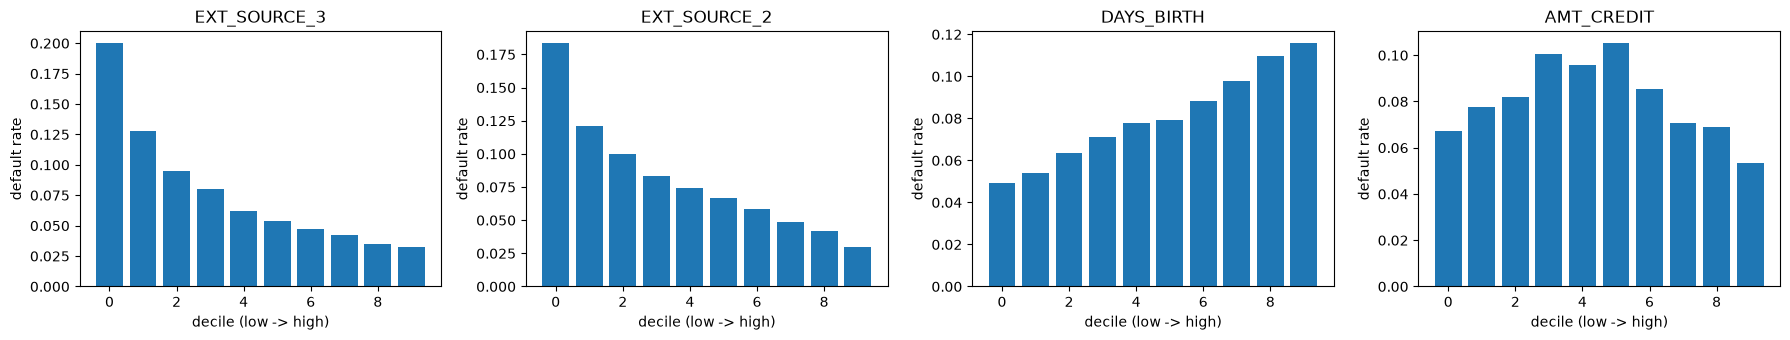

DAYS_EMPLOYED = 365243 ('1000 years', i.e. not employed) for 18.0% of applicants; their default rate is 5.40% vs 8.66%. We turn it into a flag + missing value instead of a fake number.


12

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(18, 3.5))
for ax, col in zip(axes, ["EXT_SOURCE_3", "EXT_SOURCE_2", "DAYS_BIRTH", "AMT_CREDIT"]):
    d = app[[col, "TARGET"]].dropna()
    d["bin"] = pd.qcut(d[col], 10, duplicates="drop")
    r = d.groupby("bin", observed=True)["TARGET"].mean()
    ax.bar(range(len(r)), r.values); ax.set_title(col); ax.set_xlabel("decile (low -> high)"); ax.set_ylabel("default rate")
plt.tight_layout(); plt.show()
emp = app["DAYS_EMPLOYED"] == 365243
print(f"DAYS_EMPLOYED = 365243 ('1000 years', i.e. not employed) for {emp.mean():.1%} of applicants; "
      f"their default rate is {app.loc[emp, 'TARGET'].mean():.2%} vs {app.loc[~emp, 'TARGET'].mean():.2%}. "
      "We turn it into a flag + missing value instead of a fake number.")
del app; gc.collect()

## 2-4. Features, baseline and the full model

`hcrisk.train` does it all (the same code the API is trained with):

* **features** (`hcrisk/features.py`) - per table: count / min / max / mean / sum aggregations, one-hot shares
  for categories, last-12-month windows, plus domain features: credit/income, annuity/income, loan term,
  external-score combinations, bureau debt/credit and overdue, refused-application share, days-past-due and
  underpayment on instalments, credit-card utilisation, and cross-table ratios (this loan vs. existing debt).
* **baseline** - LightGBM on the application table only.
* **full model** - LightGBM on all tables, 5-fold stratified CV with early stopping, no class weights
  (keeps probabilities calibrated).

In [5]:
report = hc_train.main(["--raw", str(RAW), "--cache", str(CACHE), "--out", str(ART),
                        "--sample", str(SAMPLE), "--quality", QUALITY])

[     0s] loading cached features C:\Users\sidda\Downloads\home-credit-risk\home-credit-risk\artifacts\features.parquet
[     6s] train 307511 applicants (8.07% default), test 48744, 672 features
[     6s] baseline: application table only (146 features)
[    78s]   baseline fold 1: AUC 0.7647  (449 trees)
[   132s]   baseline fold 2: AUC 0.7759  (326 trees)
[   192s]   baseline fold 3: AUC 0.7659  (401 trees)
[   250s]   baseline fold 4: AUC 0.7727  (372 trees)
[   301s]   baseline fold 5: AUC 0.7659  (460 trees)
[   302s] baseline OOF AUC 0.7690
[   302s] full model: all 7 tables (672 features)
[   585s]   full fold 1: AUC 0.7915  (437 trees)
[   915s]   full fold 2: AUC 0.8017  (577 trees)
[  1175s]   full fold 3: AUC 0.7924  (660 trees)
[  1390s]   full fold 4: AUC 0.7973  (512 trees)
[  1527s]   full fold 5: AUC 0.7914  (469 trees)
[  1529s] FULL OOF AUC 0.7948 (Gini 0.590, PR-AUC 0.290, KS 0.446)
[  1599s] done. artifacts in C:\Users\sidda\Downloads\home-credit-risk\home-credit-ri

In [6]:
res = pd.DataFrame([
    {"model": "baseline: application table only", "features": report["baseline"]["n_features"],
     "ROC-AUC (OOF)": report["baseline"]["oof_auc"]},
    {"model": "all 7 tables", "features": report["n_features"], "ROC-AUC (OOF)": report["oof_auc"]},
])
res["ROC-AUC (OOF)"] = res["ROC-AUC (OOF)"].round(4)
print(f"Gain from the 6 history tables: +{report['oof_auc'] - report['baseline']['oof_auc']:.4f} AUC")
print(f"fold AUCs {np.round(report['fold_auc'], 4)}  (std {report['fold_auc_std']:.4f})")
print(f"PR-AUC {report['pr_auc']:.3f} (random = {report['pr_auc_random']:.3f}) | KS {report['ks']:.3f} | "
      f"Gini {report['gini']:.3f} | Brier {report['brier']:.4f}")
res

Gain from the 6 history tables: +0.0258 AUC
fold AUCs [0.7915 0.8017 0.7924 0.7973 0.7914]  (std 0.0040)
PR-AUC 0.290 (random = 0.081) | KS 0.446 | Gini 0.590 | Brier 0.0654


,model,features,ROC-AUC (OOF)
0,baseline: application table only,146,0.7690
1,all 7 tables,672,0.7948


## 5. Evaluation
### ROC and precision-recall curves (out-of-fold)

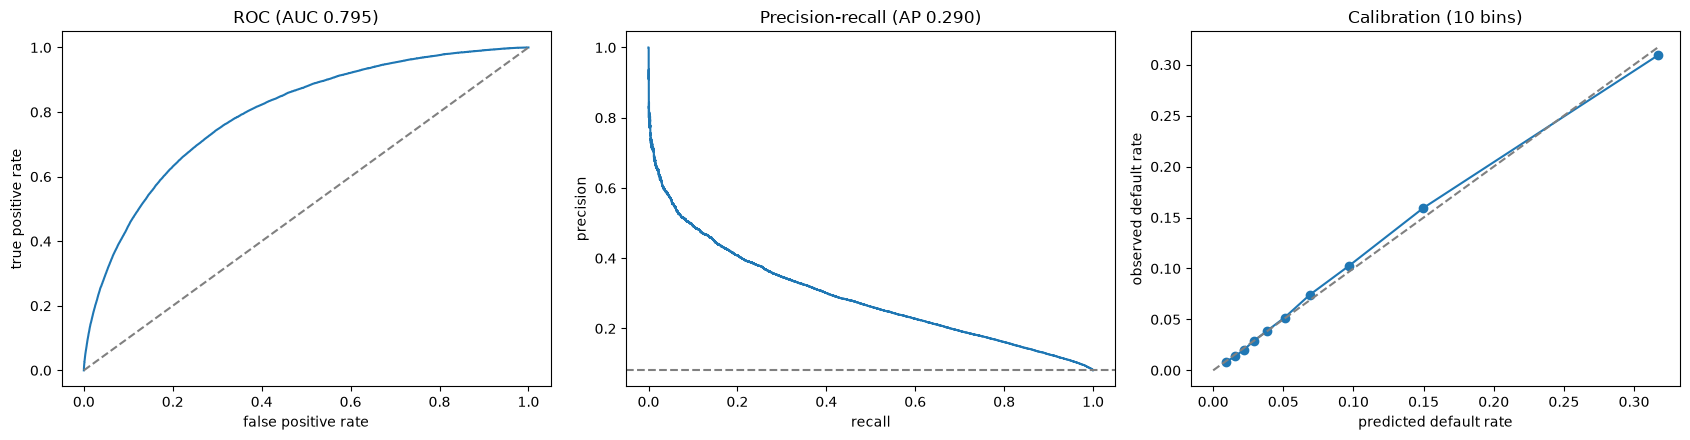

In [7]:
from sklearn.metrics import roc_curve, precision_recall_curve
oof = pd.read_parquet(ART / "oof.parquet")
y, p = oof["TARGET"].to_numpy(), oof["oof"].to_numpy()
fig, (a1, a2, a3) = plt.subplots(1, 3, figsize=(17, 4.5))
fpr, tpr, _ = roc_curve(y, p); a1.plot(fpr, tpr); a1.plot([0, 1], [0, 1], "--", c="grey")
a1.set_title(f"ROC (AUC {report['oof_auc']:.3f})"); a1.set_xlabel("false positive rate"); a1.set_ylabel("true positive rate")
pr, rc, _ = precision_recall_curve(y, p); a2.plot(rc, pr); a2.axhline(y.mean(), ls="--", c="grey")
a2.set_title(f"Precision-recall (AP {report['pr_auc']:.3f})"); a2.set_xlabel("recall"); a2.set_ylabel("precision")
cal = pd.DataFrame(report["calibration"])
a3.plot(cal.predicted, cal.observed, "o-"); m = max(cal.predicted.max(), cal.observed.max())
a3.plot([0, m], [0, m], "--", c="grey"); a3.set_title("Calibration (10 bins)")
a3.set_xlabel("predicted default rate"); a3.set_ylabel("observed default rate")
plt.tight_layout(); plt.show()

### Lift by decile: how concentrated are the defaults in the riskiest scores?

In [8]:
dec = pd.read_csv(ART / "deciles.csv")
top = dec.iloc[-1]
print(f"The riskiest 10% of applicants hold {top.share_of_all_defaults:.0%} of all defaults "
      f"(default rate {top.default_rate:.1%}, {top.lift:.1f}x the average).")
dec.round(4)

The riskiest 10% of applicants hold 38% of all defaults (default rate 30.9%, 3.8x the average).


,decile,applicants,defaults,default_rate,mean_score,min_score,max_score,lift,share_of_all_defaults
0,1,30752,248,0.0081,0.0088,0.0011,0.0124,0.0999,0.0100
1,2,30751,417,0.0136,0.0155,0.0124,0.0186,0.1680,0.0168
2,3,30751,624,0.0203,0.0219,0.0186,0.0253,0.2514,0.0251
3,4,30751,896,0.0291,0.0292,0.0253,0.0334,0.3609,0.0361
4,5,30751,1196,0.0389,0.0385,0.0334,0.0440,0.4818,0.0482
5,6,30751,1592,0.0518,0.0509,0.0440,0.0586,0.6413,0.0641
6,7,30751,2281,0.0742,0.0689,0.0586,0.0806,0.9188,0.0919
7,8,30751,3165,0.1029,0.0971,0.0806,0.1170,1.2749,0.1275
8,9,30751,4902,0.1594,0.1498,0.1170,0.1935,1.9746,0.1975
9,10,30751,9504,0.3091,0.3169,0.1935,0.9290,3.8284,0.3828


### Risk bands and a business threshold

,band,min_score,max_score,share_of_applicants,observed_default_rate
0,low,0.0000,0.0586,0.60,0.0270
1,medium,0.0586,0.1471,0.25,0.0993
2,high,0.1471,0.2810,0.10,0.2053
3,very high,0.2810,1.0000,0.05,0.3842


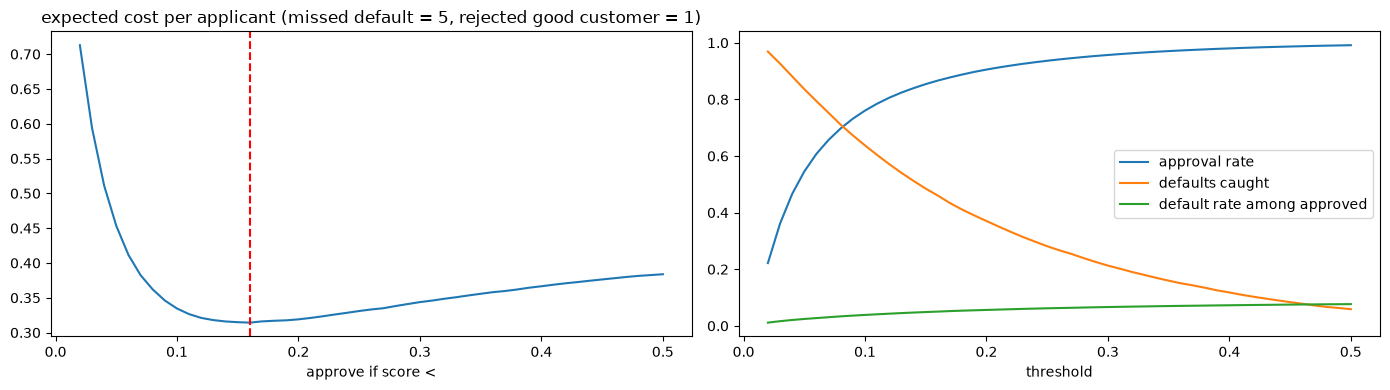

Cost-optimal threshold 0.16: approve 86.7% of applicants, catch 46.0% of defaults, default rate among approved 5.03% (vs 8.07% if everyone were approved). The 5:1 cost ratio is an assumption to agree with the business.


In [9]:
display(pd.DataFrame(report["risk_bands"]))
thr = pd.read_csv(ART / "thresholds.csv"); best = report["threshold"]["best"]
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
ax[0].plot(thr.threshold, thr.cost); ax[0].axvline(best["threshold"], ls="--", c="red")
ax[0].set_title("expected cost per applicant (missed default = 5, rejected good customer = 1)"); ax[0].set_xlabel("approve if score <")
ax[1].plot(thr.threshold, thr.approval_rate, label="approval rate"); ax[1].plot(thr.threshold, thr.defaults_caught, label="defaults caught")
ax[1].plot(thr.threshold, thr.default_rate_in_approved, label="default rate among approved"); ax[1].legend(); ax[1].set_xlabel("threshold")
plt.tight_layout(); plt.show()
print(f"Cost-optimal threshold {best['threshold']}: approve {best['approval_rate']:.1%} of applicants, "
      f"catch {best['defaults_caught']:.1%} of defaults, default rate among approved {best['default_rate_in_approved']:.2%} "
      f"(vs {report['default_rate']:.2%} if everyone were approved). The 5:1 cost ratio is an assumption to agree with the business.")

### Fairness check (monitoring only)

In [10]:
for g, rows in report["fairness"].items():
    print(g); display(pd.DataFrame(rows))

gender


,group,n,default_rate,auc,mean_score,approval_rate
0,M,105059,0.1014,0.7846,0.0989,0.8143
1,F,202448,0.0700,0.7948,0.0698,0.8936


age


,group,n,default_rate,auc,mean_score,approval_rate
0,<30,45186,0.1144,0.7684,0.1147,0.7648
1,45-60,103302,0.0656,0.7913,0.0661,0.9063
2,30-45,123737,0.0900,0.7978,0.0874,0.8450
3,60+,35286,0.0492,0.7567,0.0481,0.9558


## 6. Explainability
### What drives the model (mean |SHAP|), and which tables matter

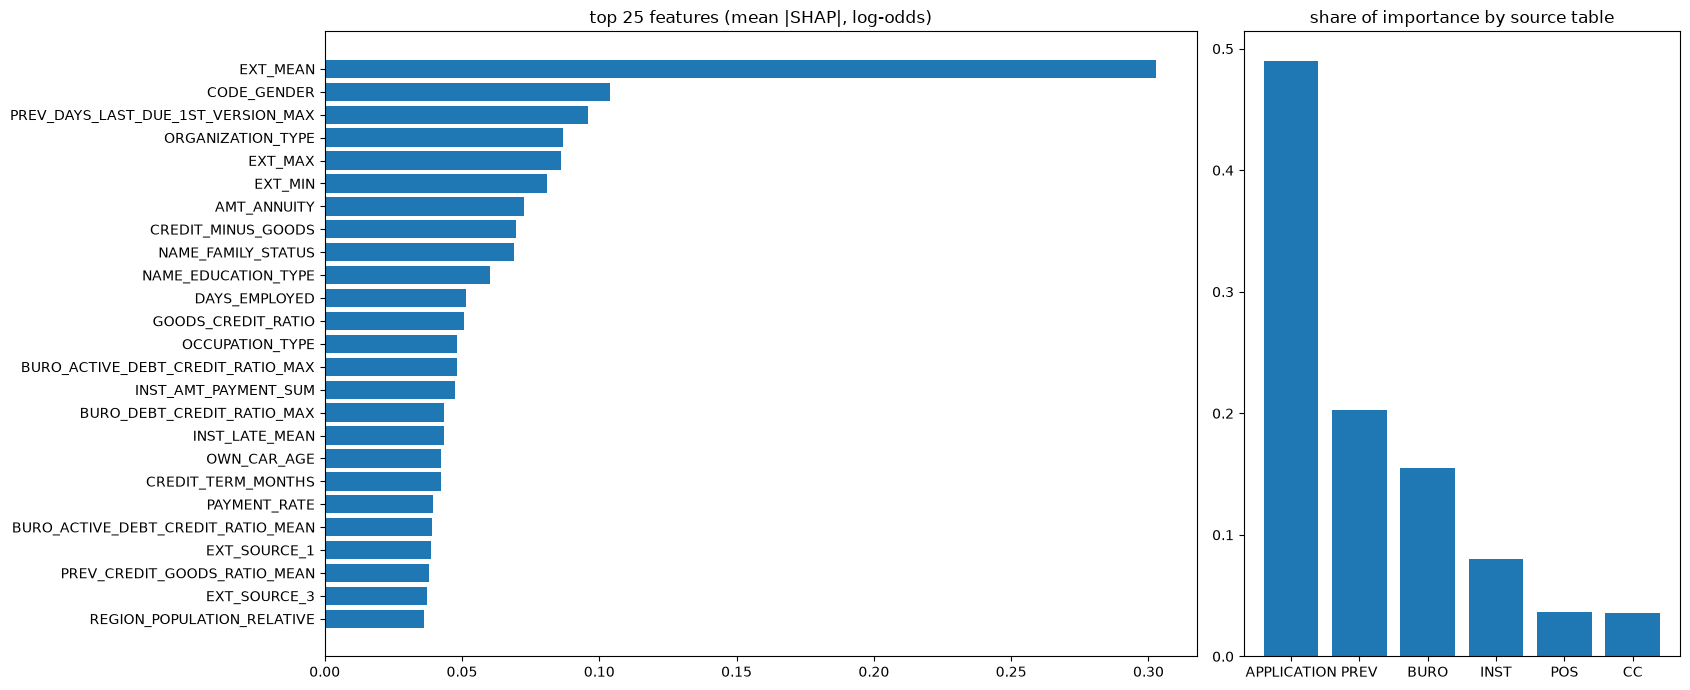

In [11]:
imp = pd.read_csv(ART / "feature_importance.csv", index_col=0)["mean_abs_shap"].head(25)[::-1]
fig, ax = plt.subplots(1, 2, figsize=(17, 7), gridspec_kw={"width_ratios": [2, 1]})
ax[0].barh(imp.index, imp.values); ax[0].set_title("top 25 features (mean |SHAP|, log-odds)")
bt = pd.Series(report["importance_by_table"]); ax[1].bar(bt.index, bt.values); ax[1].set_title("share of importance by source table")
plt.tight_layout(); plt.show()

### One applicant, explained (the same function the API's `/predict` uses)

In [12]:
os.environ["HC_ARTIFACTS"], os.environ["HC_CACHE"] = str(ART), str(CACHE)
from hcrisk.api import Scorer
scorer = Scorer(ART, CACHE)
risky_id = int(oof.sort_values("oof").iloc[-1]["SK_ID_CURR"])
out = scorer.score(scorer.by_id(risky_id))[0]
print(f"applicant {risky_id}: default probability {out['default_probability']:.1%}, band {out['risk_band']}, {out['decision']}")
pd.DataFrame(out["factors_increasing_risk"] + out["factors_decreasing_risk"])

applicant 304421: default probability 91.8%, band very high, refer to underwriter


,feature,description,value,impact_log_odds
0,EXT_MEAN,average of the 3 external credit-bureau scores,0.1707,0.6011
1,EXT_MIN,lowest external credit score,0.0006,0.3647
2,INST_LAST365_DPD_MEAN,average days late in the last 12 months,6.3,0.2124
3,ORGANIZATION_TYPE,application: ORGANIZATION_TYPE,Construction,0.2068
4,EXT_SOURCE_2,external credit score 2,0.0006,0.1905
5,NAME_EDUCATION_TYPE,education level,Incomplete higher,-0.0746
6,PREV_DAYS_LAST_DUE_1ST_VERSION_MAX,previous applications: PREV_DAYS_LAST_DUE_1ST_...,-253.0,-0.0504
7,POS_POS_LATE_MEAN,POS/cash loans: POS_POS_LATE_MEAN,0.4286,-0.0314
8,AMT_REQ_CREDIT_BUREAU_QRT,application: AMT_REQ_CREDIT_BUREAU_QRT,1.0,-0.0303
9,BURO_CREDIT_TYPE_CONSUMER_CREDIT_MEAN,credit bureau: BURO_CREDIT_TYPE_CONSUMER_CREDI...,0.0,-0.0295


In [13]:
# what-if: the same applicant asking for half the credit
raw_credit = float(scorer.raw_app.loc[risky_id, "AMT_CREDIT"]) if scorer.raw_app is not None else None
if raw_credit:
    w = scorer.score(scorer.by_id(risky_id, {"AMT_CREDIT": raw_credit / 2, "AMT_ANNUITY":
                                             float(scorer.raw_app.loc[risky_id, "AMT_ANNUITY"]) / 2}))[0]
    print(f"credit {raw_credit:,.0f} -> {raw_credit/2:,.0f}: probability {out['default_probability']:.1%} -> {w['default_probability']:.1%}")

credit 364,896 -> 182,448: probability 91.8% -> 87.1%


## Summary

Run the cell below for the numbers of this run. Things to discuss:

* **The history tables add real signal** on top of the application form (baseline vs. full AUC), led by
  instalment behaviour (late / underpaid payments), bureau debt and previous refusals; the external scores
  remain the strongest single features.
* **Ranking quality:** OOF ROC-AUC with a small fold-to-fold spread; the riskiest decile concentrates
  defaults several times above average.
* **Probabilities are calibrated** (no class re-weighting), so risk bands and the cost-based threshold
  are meaningful as rates.
* **Limitations / next steps:** the threshold cost ratio is an assumption; fairness is monitored, not
  enforced; next would be hyper-parameter search (Optuna), more time-window features, a second model type
  (CatBoost) for an ensemble, and monitoring for drift once deployed.

In [14]:
print(json.dumps({k: report[k] for k in ("n_train", "default_rate", "n_features", "oof_auc", "pr_auc", "ks", "brier")}
                 | {"baseline_auc": report["baseline"]["oof_auc"], "importance_by_table": report["importance_by_table"]},
                 indent=1))

{
 "n_train": 307511,
 "default_rate": 0.08072881945686496,
 "n_features": 672,
 "oof_auc": 0.7948065955900426,
 "pr_auc": 0.29004755958592826,
 "ks": 0.4463069413702744,
 "brier": 0.06541304793988152,
 "baseline_auc": 0.7689665864571096,
 "importance_by_table": {
  "APPLICATION": 0.4898,
  "PREV": 0.2024,
  "BURO": 0.1549,
  "INST": 0.0801,
  "POS": 0.0369,
  "CC": 0.036
 }
}
